This notebook accompanies my note on [backpropagation](index.qmd). It turns the derivation into code, using the same network and notation:

1. **The network** — 4 inputs, hidden layers of 5 and 3 nodes, and 2 outputs, with weights $W^{[1]}, W^{[2]}, W^{[3]}$.
2. **Forward pass** — $x^{[l]} = f^{[l]}(a^{[l]})$ with $a^{[l]} = W^{[l]} x^{[l-1]}$.
3. **Backward pass** — the deltas $\delta^{[l]}$ and the gradients $\partial L / \partial W^{[l]} = \delta^{[l]} (x^{[l-1]})^T$, checked against the element-by-element formula from my notes and against finite differences.
4. **Training** — the update $W_\text{new} = W - \eta\, \partial L / \partial W$, first on a single data point (as in the notes), then on a small dataset.

As in my notes, there are no biases and the loss is $L = \tfrac12 e^T e$ with $e = t - x^{[3]}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110

SIZES = [4, 5, 3, 2]          # x[0] (input), x[1], x[2], x[3] (output)
L_LAYERS = len(SIZES) - 1     # 3 weight matrices
LAYER_COLORS = ["#1f77b4", "#2ca02c", "#d62728"]   # W[1], W[2], W[3]

## 1. The network

Each hidden and output node is drawn split in two, as in my notes: the left half holds the pre-activation $a^{[l]}_i$ and the right half the output $x^{[l]}_i = f^{[l]}(a^{[l]}_i)$. Weight matrix $W^{[l]}$ maps layer $l-1$ to layer $l$, so it has one row per node in layer $l$ and one column per node in layer $l-1$.

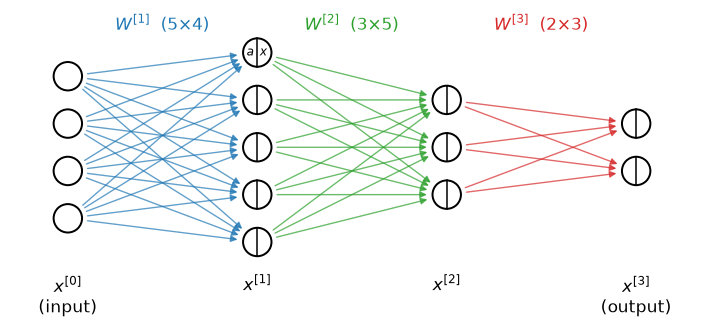

In [2]:
#| label: fig-network
#| fig-cap: "The 4-5-3-2 network from my notes. Edges are colored by weight matrix; each split node holds its pre-activation $a$ (left) and output $x$ (right)."
def node_positions(sizes):
    pos = []
    for l, n in enumerate(sizes):
        ys = np.linspace(1, 0, n) if n > 1 else np.array([0.5])
        ys = 0.5 + (ys - 0.5) * (n - 1) / (max(sizes) - 1)
        pos.append(np.column_stack([np.full(n, float(l)), ys]))
    return pos

def draw_network(ax, sizes=SIZES):
    pos = node_positions(sizes)
    r = 0.075
    for l in range(1, len(sizes)):
        for j, dst in enumerate(pos[l]):
            for i, src in enumerate(pos[l - 1]):
                ax.annotate("", xy=dst, xytext=src,
                            arrowprops=dict(arrowstyle="-|>", color=LAYER_COLORS[l - 1],
                                            lw=0.9, alpha=0.7, shrinkA=13, shrinkB=13,
                                            mutation_scale=9))
        mid = (pos[l - 1][0] + pos[l][0]) / 2
        ax.text(mid[0], 1.12, rf"$W^{{[{l}]}}$  ({sizes[l]}$\times${sizes[l-1]})",
                ha="center", fontsize=11, color=LAYER_COLORS[l - 1])
    for l, layer in enumerate(pos):
        for (x, y) in layer:
            ax.add_patch(plt.Circle((x, y), r, fc="white", ec="black", lw=1.3, zorder=3))
            if l > 0:
                ax.plot([x, x], [y - r, y + r], color="black", lw=1, zorder=4)
        ax.text(layer[0, 0], -0.17, rf"$x^{{[{l}]}}$" + ("\n(input)" if l == 0 else "\n(output)" if l == len(sizes) - 1 else ""),
                ha="center", va="top", fontsize=11)
    x, y = pos[1][0]
    ax.text(x - 0.035, y, r"$a$", ha="center", va="center", fontsize=8, zorder=5)
    ax.text(x + 0.035, y, r"$x$", ha="center", va="center", fontsize=8, zorder=5)
    ax.set_xlim(-0.3, len(sizes) - 0.7); ax.set_ylim(-0.38, 1.22)
    ax.set_aspect("equal"); ax.axis("off")

fig, ax = plt.subplots(figsize=(8, 4.6))
draw_network(ax)
plt.show()

## 2. Forward pass

Following page 1 of my notes, each layer computes $a^{[l]} = W^{[l]} x^{[l-1]}$ and then $x^{[l]} = f^{[l]}(a^{[l]})$, so the whole network is the nested function

$$x^{[3]} = f^{[3]}\Big(W^{[3]} f^{[2]}\big(W^{[2]} f^{[1]}(W^{[1]} x^{[0]})\big)\Big).$$

I use $\tanh$ in the hidden layers and the sigmoid at the output, so the outputs lie in $(0, 1)$ like the targets below. The backward pass needs each activation's derivative $f'$, so I store them together. The forward pass keeps every $a^{[l]}$ and $x^{[l]}$, since the backward pass reuses them.

In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

ACT = {
    "tanh":    (np.tanh, lambda z: 1 - np.tanh(z) ** 2),
    "sigmoid": (sigmoid, lambda z: sigmoid(z) * (1 - sigmoid(z))),
}
ACTS = ["tanh", "tanh", "sigmoid"]   # f[1], f[2], f[3]

def init_weights(seed=0):
    rng = np.random.default_rng(seed)
    # W[l] has shape (nodes in layer l) x (nodes in layer l-1); scaled so tanh starts unsaturated
    return [rng.normal(0, 1 / np.sqrt(SIZES[l]), size=(SIZES[l + 1], SIZES[l]))
            for l in range(L_LAYERS)]

def forward(Ws, x0):
    """Return lists a[1..3] and x[0..3] (a[0] is unused)."""
    xs, as_ = [x0], [None]
    for l, W in enumerate(Ws, start=1):
        a = W @ xs[-1]
        as_.append(a)
        xs.append(ACT[ACTS[l - 1]][0](a))
    return as_, xs

def loss(Ws, x0, t):
    e = t - forward(Ws, x0)[1][-1]
    return 0.5 * e @ e

Ws = init_weights()
x0 = np.array([0.5, -1.0, 0.8, 0.2])
t = np.array([1.0, 0.0])
as_, xs = forward(Ws, x0)
for l in range(1, 4):
    print(f"a[{l}] = {np.round(as_[l], 3)}   x[{l}] = {np.round(xs[l], 3)}")
print(f"\ntarget t = {t},  loss L = {loss(Ws, x0, t):.4f}")

a[1] = [ 0.364  0.302  0.212 -1.043  0.291]   x[1] = [ 0.349  0.293  0.208 -0.779  0.283]
a[2] = [ 0.089  0.019 -0.361]   x[2] = [ 0.088  0.019 -0.346]
a[3] = [0.037 0.308]   x[3] = [0.509 0.576]

target t = [1. 0.],  loss L = 0.2865


## 3. Backward pass

### The output layer, element by element

Pages 2–3 of my notes work out one entry of $\partial L / \partial W^{[3]}$ at a time. Only output $i$ depends on $w^{[3]}_{ij}$, and within $a^{[3]}_i = \sum_k w^{[3]}_{ik} x^{[2]}_k$ only the $k = j$ term does, which leaves

$$\frac{\partial L}{\partial w^{[3]}_{ij}} = -\big(t_i - x^{[3]}_i\big)\, f'^{[3]}\big(a^{[3]}_i\big)\, x^{[2]}_j .$$

Here is that formula as a double loop over the $2 \times 3$ entries:

In [4]:
def grad_W3_elementwise(Ws, x0, t):
    as_, xs = forward(Ws, x0)
    fprime = ACT[ACTS[2]][1]
    G = np.zeros_like(Ws[2])
    for i in range(SIZES[3]):
        for j in range(SIZES[2]):
            G[i, j] = -(t[i] - xs[3][i]) * fprime(as_[3][i]) * xs[2][j]
    return G

print(np.round(grad_W3_elementwise(Ws, x0, t), 5))

[[-0.01085 -0.0023   0.04245]
 [ 0.01245  0.00264 -0.04871]]


### All layers with the delta recursion

Collecting those entries into a matrix gives the outer product $-\big(t - x^{[3]}\big) \odot f'^{[3]}(a^{[3]})\, (x^{[2]})^T$. Naming the first factor $\delta^{[3]}$ and passing it backward through the transposed weights gives every layer's gradient:

$$\delta^{[3]} = -\big(t - x^{[3]}\big) \odot f'^{[3]}\big(a^{[3]}\big), \qquad
\delta^{[l]} = \big(W^{[l+1]}\big)^T \delta^{[l+1]} \odot f'^{[l]}\big(a^{[l]}\big), \qquad
\frac{\partial L}{\partial W^{[l]}} = \delta^{[l]} \big(x^{[l-1]}\big)^T.$$

In [5]:
def backward(Ws, x0, t):
    """Return the gradients dL/dW[l] and the deltas delta[l], for l = 1..3."""
    as_, xs = forward(Ws, x0)
    deltas = [None] * (L_LAYERS + 1)
    deltas[3] = -(t - xs[3]) * ACT[ACTS[2]][1](as_[3])
    for l in (2, 1):
        deltas[l] = (Ws[l].T @ deltas[l + 1]) * ACT[ACTS[l - 1]][1](as_[l])
    grads = [np.outer(deltas[l], xs[l - 1]) for l in (1, 2, 3)]
    return grads, deltas

grads, deltas = backward(Ws, x0, t)
for l in (1, 2, 3):
    print(f"delta[{l}] = {np.round(deltas[l], 5)}   dL/dW[{l}] shape {grads[l-1].shape}")
print("\nmatrix form matches the element-by-element formula for W[3]:",
      np.allclose(grads[2], grad_W3_elementwise(Ws, x0, t)))

delta[1] = [ 0.03676 -0.02257 -0.07137 -0.0189   0.02215]   dL/dW[1] shape (5, 4)
delta[2] = [ 0.03823  0.16758 -0.08196]   dL/dW[2] shape (3, 5)
delta[3] = [-0.12265  0.14073]   dL/dW[3] shape (2, 3)

matrix form matches the element-by-element formula for W[3]: True


Each gradient is an **outer product**, so it has rank 1: every row is a multiple of $(x^{[l-1]})^T$ and every column a multiple of $\delta^{[l]}$. The weight $w^{[l]}_{ij}$ gets a large gradient only when the node it feeds has a large error signal $\delta^{[l]}_i$ **and** the node it comes from has a large output $x^{[l-1]}_j$.

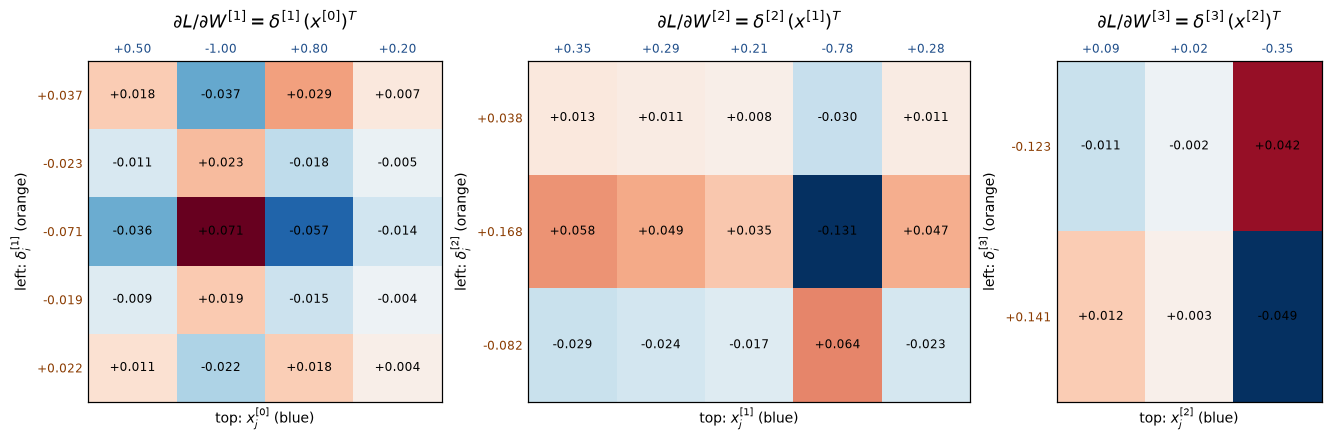

In [6]:
#| label: fig-outer-product
#| fig-cap: "Each gradient $\\partial L/\\partial W^{[l]}$ (heatmap) is the outer product of the delta $\\delta^{[l]}$ (left column) and the previous layer's output $x^{[l-1]}$ (top row)."
fig, axes = plt.subplots(1, 3, figsize=(12, 3.9), layout="constrained",
                         gridspec_kw={"width_ratios": [4, 5, 3]})
_, xs = forward(Ws, x0)
for ax, l in zip(axes, (1, 2, 3)):
    G, d, xp = grads[l - 1], deltas[l], xs[l - 1]
    m = np.abs(G).max()
    ax.imshow(G, cmap="RdBu_r", vmin=-m, vmax=m, aspect="auto")
    for i in range(G.shape[0]):
        for j in range(G.shape[1]):
            ax.text(j, i, f"{G[i, j]:+.3f}", ha="center", va="center", fontsize=8)
    ax.set_yticks(range(G.shape[0]), [f"{v:+.3f}" for v in d])
    ax.set_xticks(range(G.shape[1]), [f"{v:+.2f}" for v in xp])
    ax.xaxis.tick_top()
    for lab in ax.get_yticklabels(): lab.set_color("#8a3b00")
    for lab in ax.get_xticklabels(): lab.set_color("#1f4e8a")
    ax.tick_params(length=0, labelsize=8)
    ax.set_title(rf"$\partial L/\partial W^{{[{l}]}} = \delta^{{[{l}]}}\,(x^{{[{l-1}]}})^T$", pad=10)
    ax.set_xlabel(rf"top: $x^{{[{l-1}]}}_j$ (blue)", fontsize=9)
    ax.set_ylabel(rf"left: $\delta^{{[{l}]}}_i$ (orange)", fontsize=9)
plt.show()

### Gradient check

The derivation is only useful if it is right, so I compare every entry of every gradient with a centered finite difference,

$$\frac{\partial L}{\partial w} \approx \frac{L(w + \varepsilon) - L(w - \varepsilon)}{2\varepsilon}, \qquad \varepsilon = 10^{-5}.$$

This costs two forward passes per weight (82 for this network), which is why backpropagation, at the cost of one forward and one backward pass, is what training actually uses.

In [7]:
def numerical_grads(Ws, x0, t, eps=1e-5):
    out = []
    for W in Ws:
        G = np.zeros_like(W)
        for idx in np.ndindex(W.shape):
            old = W[idx]
            W[idx] = old + eps; lp = loss(Ws, x0, t)
            W[idx] = old - eps; lm = loss(Ws, x0, t)
            W[idx] = old
            G[idx] = (lp - lm) / (2 * eps)
        out.append(G)
    return out

num = numerical_grads(Ws, x0, t)
for l in (1, 2, 3):
    rel = np.linalg.norm(grads[l-1] - num[l-1]) / np.linalg.norm(grads[l-1] + num[l-1])
    print(f"W[{l}]: {grads[l-1].size:2d} weights, relative error {rel:.1e}")

W[1]: 20 weights, relative error 6.5e-11
W[2]: 15 weights, relative error 2.2e-11
W[3]:  6 weights, relative error 3.1e-11


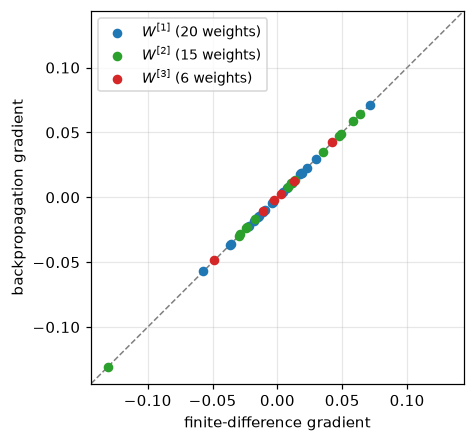

In [8]:
#| label: fig-gradcheck
#| fig-cap: "Backpropagation versus finite differences for all 41 weights. Every point lies on the diagonal."
fig, ax = plt.subplots(figsize=(4.6, 4.4))
for l in (1, 2, 3):
    ax.scatter(num[l-1].ravel(), grads[l-1].ravel(), s=28, color=LAYER_COLORS[l-1],
               label=rf"$W^{{[{l}]}}$ ({grads[l-1].size} weights)", zorder=3)
lim = 1.1 * max(np.abs(g).max() for g in grads)
ax.plot([-lim, lim], [-lim, lim], color="gray", lw=1, ls="--", zorder=1)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
ax.set_xlabel("finite-difference gradient"); ax.set_ylabel("backpropagation gradient")
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.show()

## 4. Training

### One data point

My notes end with the update rule $W_\text{new} = W - \eta\, \partial L/\partial W$, applied to every weight matrix. Repeating it on the single data point above drives the outputs toward the target $t = (1, 0)$.

In [9]:
def train_single(Ws, x0, t, eta=0.5, steps=300):
    Ws = [W.copy() for W in Ws]
    hist_L, hist_y = [], []
    for _ in range(steps):
        hist_L.append(loss(Ws, x0, t))
        hist_y.append(forward(Ws, x0)[1][-1])
        grads, _ = backward(Ws, x0, t)
        Ws = [W - eta * G for W, G in zip(Ws, grads)]
    return Ws, np.array(hist_L), np.array(hist_y)

Ws_single, hist_L, hist_y = train_single(Ws, x0, t)
print(f"loss: {hist_L[0]:.4f} -> {hist_L[-1]:.5f}")
print(f"outputs: {np.round(hist_y[0], 3)} -> {np.round(hist_y[-1], 3)}  (target {t})")

loss: 0.2865 -> 0.00177
outputs: [0.509 0.576] -> [0.953 0.036]  (target [1. 0.])


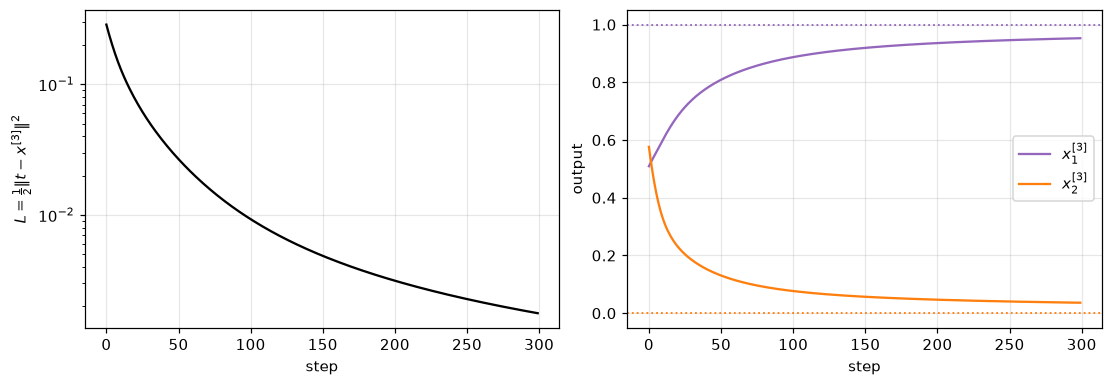

In [10]:
#| label: fig-train-single
#| fig-cap: "Gradient descent on the single data point ($\\eta = 0.5$). Left: the loss. Right: the two outputs approaching their targets (dotted)."
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4), layout="constrained")
a1.plot(hist_L, color="black"); a1.set_yscale("log")
a1.set_xlabel("step"); a1.set_ylabel(r"$L = \frac{1}{2}\|t - x^{[3]}\|^2$"); a1.grid(alpha=0.3)
for k, c in enumerate(["#9467bd", "#ff7f0e"]):
    a2.plot(hist_y[:, k], color=c, label=rf"$x^{{[3]}}_{k+1}$")
    a2.axhline(t[k], color=c, ls=":", lw=1.2)
a2.set_xlabel("step"); a2.set_ylabel("output"); a2.set_ylim(-0.05, 1.05)
a2.legend(); a2.grid(alpha=0.3)
plt.show()

### A small dataset

With $N$ data points the loss becomes a sum, $L = \sum_n \tfrac12 \|t_n - x^{[3]}_n\|^2$, and because differentiation is linear its gradient is the sum of the per-point gradients. Nothing else in the derivation changes. I sum `backward` over the points (for speed, the same computation stacks the points as columns of a matrix).

The toy task has 4 random inputs and 2 yes/no outputs:

- $t_1 = 1$ if $x_1 + x_2 > x_3 + x_4$ (a linear rule);
- $t_2 = 1$ if $x_1$ and $x_4$ have the same sign (an XOR-like rule that no single linear boundary can learn).

In [11]:
rng = np.random.default_rng(1)
N = 200
X = rng.uniform(-1, 1, size=(N, 4))
T = np.column_stack([(X[:, 0] + X[:, 1] > X[:, 2] + X[:, 3]),
                     (X[:, 0] * X[:, 3] > 0)]).astype(float)
split = 150
Xtr, Ttr, Xte, Tte = X[:split], T[:split], X[split:], T[split:]

def batch_backward(Ws, X, T):
    """Same as summing backward() over the rows of X, with points stacked as columns."""
    xs, as_ = [X.T], [None]
    for l, W in enumerate(Ws, start=1):
        as_.append(W @ xs[-1]); xs.append(ACT[ACTS[l - 1]][0](as_[-1]))
    d = -(T.T - xs[3]) * ACT[ACTS[2]][1](as_[3])
    grads = [None] * 3
    for l in (3, 2, 1):
        grads[l - 1] = d @ xs[l - 1].T
        if l > 1:
            d = (Ws[l - 1].T @ d) * ACT[ACTS[l - 2]][1](as_[l - 1])
    L = 0.5 * np.sum((T.T - xs[3]) ** 2)
    return grads, L, xs[3].T

g_loop = [sum(backward(Ws, x, tt)[0][l] for x, tt in zip(Xtr, Ttr)) for l in range(3)]
g_batch = batch_backward(Ws, Xtr, Ttr)[0]
print("batched gradient equals the sum of per-point gradients:",
      all(np.allclose(a, b) for a, b in zip(g_loop, g_batch)))

batched gradient equals the sum of per-point gradients: True


In [12]:
def accuracy(Ws, X, T, backward_fn=batch_backward):
    Y = backward_fn(Ws, X, T)[2]
    return ((Y > 0.5) == (T > 0.5)).mean(axis=0)

def train_batch(W, backward_fn, eta=0.02, epochs=3000):
    hist = []
    for ep in range(epochs + 1):
        grads, L, _ = backward_fn(W, Xtr, Ttr)
        if ep % 20 == 0:
            hist.append((ep, L / split, *accuracy(W, Xte, Tte, backward_fn)))
        W = [Wl - eta * G for Wl, G in zip(W, grads)]
    return W, np.array(hist)

W_nobias, hist_nobias = train_batch(init_weights(seed=3), batch_backward)
print(f"mean loss per point: {hist_nobias[0, 1]:.3f} -> {hist_nobias[-1, 1]:.3f}")
print(f"test accuracy  t1 (linear rule): {hist_nobias[-1, 2]:.0%}   t2 (XOR-like rule): {hist_nobias[-1, 3]:.0%}")

mean loss per point: 0.256 -> 0.092
test accuracy  t1 (linear rule): 92%   t2 (XOR-like rule): 56%


The linear rule $t_1$ is learned quickly, but $t_2$ stays near chance (50%) however long I train. This isn't a bad learning rate or an unlucky start: this network **cannot** represent $t_2$.

Without biases, every layer maps $-x$ to the negative of what it maps $x$ to. $W(-x) = -Wx$ and $\tanh$ is odd, so $x^{[2]}(-x) = -x^{[2]}(x)$ and $a^{[3]}(-x) = -a^{[3]}(x)$. After the sigmoid, $x^{[3]}_k(-x) = 1 - x^{[3]}_k(x)$: whatever the network predicts for $x$, it predicts the **opposite** for $-x$.

- $t_1$ is compatible with that, since flipping the sign of $x$ flips the label.
- $t_2$ is not. $x_1$ and $x_4$ have the same sign exactly when $-x_1$ and $-x_4$ do, so $x$ and $-x$ share a label, and the network gets at most one of each such pair right.

### Adding biases

This is the bias my notes leave out. As in the [forward-propagation note](../forward-propagation/index.qmd), I fold it into the weights by giving every layer a constant input $1$. Each $W^{[l]}$ gets one extra column (its biases $b^{[l]}$), and $a^{[l]} = W^{[l]} \begin{bmatrix} x^{[l-1]} \\ 1 \end{bmatrix}$. The backward pass changes in two small ways:

- The gradient uses the extended input, $\partial L / \partial W^{[l]} = \delta^{[l]} \begin{bmatrix} x^{[l-1]} \\ 1 \end{bmatrix}^T$, so the bias column's gradient is just $\delta^{[l]}$.
- The recursion passes $\delta$ back through the weights only, not the bias column, because the constant $1$ has no earlier layer to pass the gradient to.

In [13]:
def with_ones(x):
    return np.vstack([x, np.ones((1, x.shape[1]))])

def init_weights_bias(seed=0):
    rng = np.random.default_rng(seed)
    return [rng.normal(0, 1 / np.sqrt(SIZES[l]), size=(SIZES[l + 1], SIZES[l] + 1))
            for l in range(L_LAYERS)]

def batch_backward_bias(Ws, X, T):
    xs, as_ = [X.T], [None]
    for l, W in enumerate(Ws, start=1):
        as_.append(W @ with_ones(xs[-1])); xs.append(ACT[ACTS[l - 1]][0](as_[-1]))
    d = -(T.T - xs[3]) * ACT[ACTS[2]][1](as_[3])
    grads = [None] * 3
    for l in (3, 2, 1):
        grads[l - 1] = d @ with_ones(xs[l - 1]).T
        if l > 1:
            d = (Ws[l - 1][:, :-1].T @ d) * ACT[ACTS[l - 2]][1](as_[l - 1])
    L = 0.5 * np.sum((T.T - xs[3]) ** 2)
    return grads, L, xs[3].T

W_bias, hist_bias = train_batch(init_weights_bias(seed=6), batch_backward_bias)
print(f"mean loss per point: {hist_bias[0, 1]:.3f} -> {hist_bias[-1, 1]:.3f}")
print(f"test accuracy  t1 (linear rule): {hist_bias[-1, 2]:.0%}   t2 (XOR-like rule): {hist_bias[-1, 3]:.0%}")

mean loss per point: 0.298 -> 0.014
test accuracy  t1 (linear rule): 96%   t2 (XOR-like rule): 96%


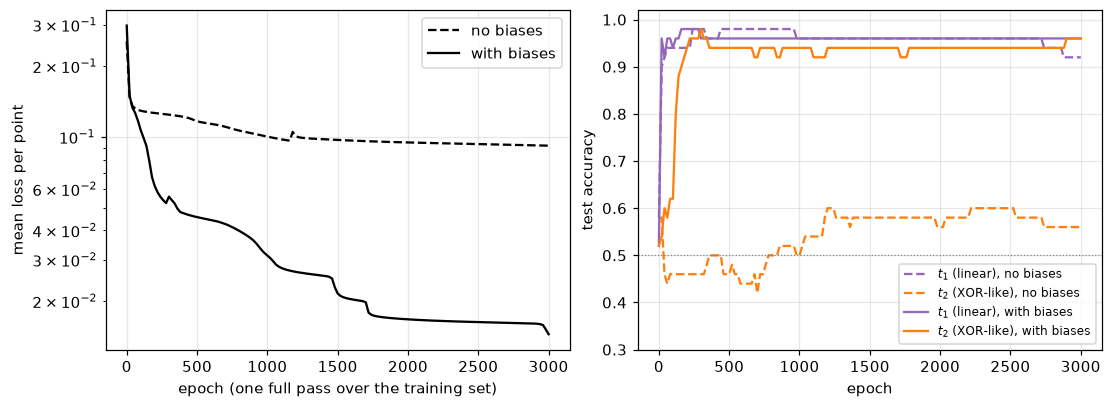

In [14]:
#| label: fig-train-batch
#| fig-cap: "Full-batch gradient descent on 150 training points, without biases (dashed) and with biases (solid). Left: mean loss per point. Right: accuracy on 50 held-out test points for each output."
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
for h, ls, name in ((hist_nobias, "--", "no biases"), (hist_bias, "-", "with biases")):
    a1.plot(h[:, 0], h[:, 1], color="black", ls=ls, label=name)
    a2.plot(h[:, 0], h[:, 2], color="#9467bd", ls=ls, label=rf"$t_1$ (linear), {name}")
    a2.plot(h[:, 0], h[:, 3], color="#ff7f0e", ls=ls, label=rf"$t_2$ (XOR-like), {name}")
a1.set_yscale("log"); a1.legend()
a1.set_xlabel("epoch (one full pass over the training set)"); a1.set_ylabel("mean loss per point")
a1.grid(alpha=0.3)
a2.axhline(0.5, color="gray", lw=0.8, ls=":")
a2.set_xlabel("epoch"); a2.set_ylabel("test accuracy"); a2.set_ylim(0.3, 1.02)
a2.legend(loc="lower right", fontsize=8); a2.grid(alpha=0.3)
plt.show()

With biases, $t_2$ is learned too: the hidden layers can now place their boundaries away from the origin and build features that make the XOR-like rule separable.

## Summary

- **Forward:** $a^{[l]} = W^{[l]} x^{[l-1]}$, $x^{[l]} = f^{[l]}(a^{[l]})$; keep every $a^{[l]}$ and $x^{[l]}$.
- **Backward:** $\delta^{[3]} = -(t - x^{[3]}) \odot f'^{[3]}(a^{[3]})$, then $\delta^{[l]} = (W^{[l+1]})^T \delta^{[l+1]} \odot f'^{[l]}(a^{[l]})$.
- **Gradients:** $\partial L / \partial W^{[l]} = \delta^{[l]} (x^{[l-1]})^T$, which matches finite differences to about $10^{-10}$.
- **Update:** $W^{[l]} \leftarrow W^{[l]} - \eta\, \partial L / \partial W^{[l]}$ for every layer; for a dataset, sum the per-point gradients.
- **Biases matter:** without them, a network with odd activations such as $\tanh$ can only learn odd functions. With them, each bias gradient is simply $\delta^{[l]}$.